# Notebook 3 — Per-File Analysis

**Purpose:** Deep-dive per audio file — identify which files each method excels or struggles on.

**Input:** Same `stdout.log` files as Notebooks 1 & 2.

**Outputs:**
- Per-file F-measure bar (grouped, all experiments)
- Per-file TP / FP / FN stacked bar per experiment
- Species/subset breakdown (BUK, ME, R4, RD, PW aggregated)
- Per-subset recall heatmap (how many events each method finds)
- FP count per file — noisiest files
- Recall per file heatmap across experiments

## 0 — Configuration

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path(".").resolve()))
import parse_logs as pl

# ── Experiment log paths ───────────────────────────────────────────────────
EXPERIMENT_LOGS = {
    "Baseline":            "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/baseline_seed1234/2026-09-17_09-08-46/stdout.log",  # e.g. "../logs/experiments/runs/baseline/2026-.../stdout.log"
    "CIFE":                "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/cife_seed1234/2026-09-17_22-11-22/stdout.log",
    "Slot Uniform":        "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/slot_uniform_seed1234/2026-09-18_12-05-18/stdout.log",
    "Phase 1 (Random)":    "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/phase1_random_seed1234/2026-09-18_05-15-56/stdout.log",
    "Phase 2 (Energy)":    "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/phase2_energy_seed1234/2026-09-18_16-56-51/stdout.log",
    "Phase 3 (Activation)": "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/phase3_seed1234_output.log",
    "AFRI (Direct)": "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/afri_direct_seed1234/2026-09-19_14-20-53/stdout.log",
    "AFRI (Inverse)": "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/afri_inverse_seed1234/2026-09-19_20-45-13/stdout.log",
}


logs_to_parse = {k: v for k, v in EXPERIMENT_LOGS.items() if v is not None}
print(f"Parsing {len(logs_to_parse)} experiment(s)...")

Parsing 8 experiment(s)...


## 1 — Load & Parse

In [2]:
experiments = pl.load_experiments(logs_to_parse)

  ✓ Baseline                        fmeasure=16.615
  ✓ CIFE                            fmeasure=15.296
  ✓ Slot Uniform                    fmeasure=15.392
  ✓ Phase 1 (Random)                fmeasure=15.618
  ✓ Phase 2 (Energy)                fmeasure=15.434
  ✓ Phase 3 (Activation)            fmeasure=15.304
  ✓ AFRI (Direct)                   fmeasure=15.502
  ✓ AFRI (Inverse)                  fmeasure=15.613


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.alpha": 0.4,
    "font.size": 10,
})

COLORS = plt.cm.tab10.colors
exp_labels = list(experiments.keys())

df_pf = pl.per_file_df(experiments)
print(f"Per-file rows: {len(df_pf)}")
print(f"Files found  : {df_pf['filename'].nunique()}")
print(f"Subsets      : {sorted(df_pf['subset'].unique())}")
df_pf.head()

Per-file rows: 336
Files found  : 42
Subsets      : ['HB', 'ME', 'PB', 'PB24', 'PW', 'RD']


,from_backfill,experiment,filename,subset,TP,FP,FN,total_n_pos_events,precision,recall,fmeasure
0,False,Baseline,BUK1_20181011_001004.wav,PB,3,31,28,31,0.088235,0.096774,0.092308
1,False,Baseline,BUK4_20161011_000804.wav,PB,0,164,47,47,0.000000,0.000000,0.000000
2,False,Baseline,BUK4_20161031_232104a.wav,PB24,22,20,155,177,0.523810,0.124294,0.200913
3,False,Baseline,BUK4_20171022_004304a.wav,PB,5,7,12,17,0.416667,0.294118,0.344828
4,False,Baseline,BUK5_20161101_002104a.wav,PB,19,152,69,88,0.111111,0.215909,0.146718


## 2 — Per-File F-measure (grouped bar)

One group of bars per audio file, one bar per experiment.

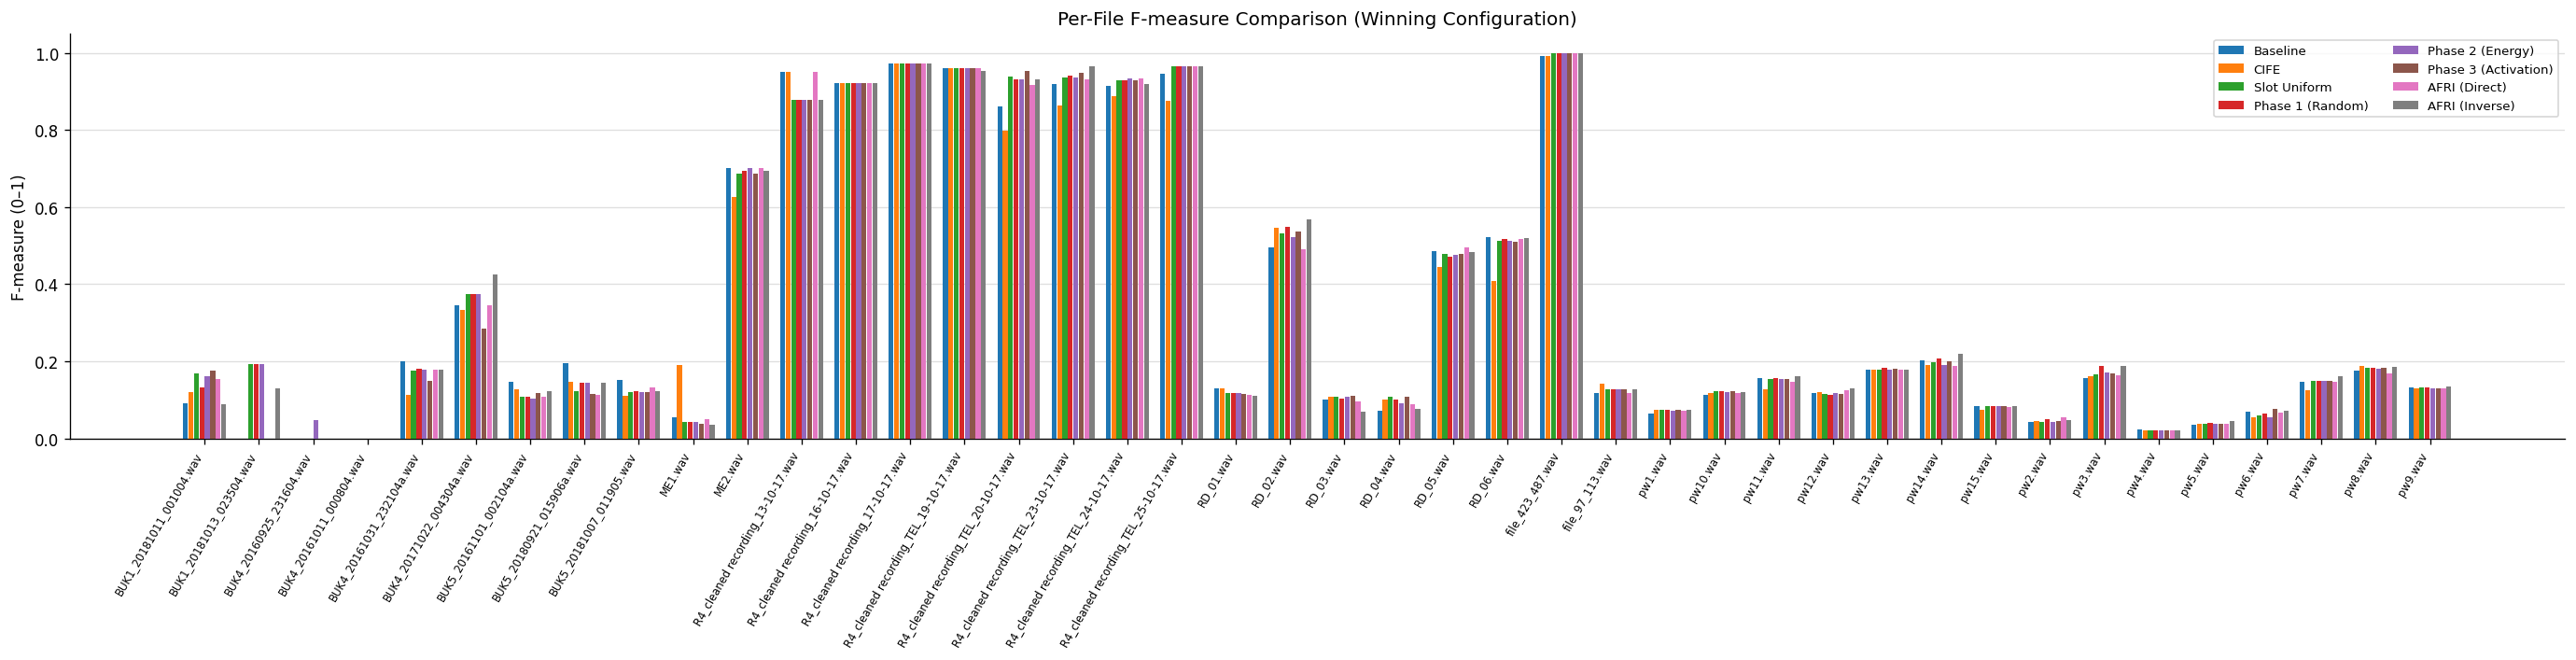

In [4]:
if df_pf.empty:
    print("Per-file data not available.")
else:
    all_files = sorted(df_pf["filename"].unique())
    n_files = len(all_files)
    n_exp = len(exp_labels)
    x = np.arange(n_files)
    group_w = 0.8
    bar_w = group_w / n_exp

    fig, ax = plt.subplots(figsize=(max(14, n_files * 0.55), 6))

    for i_e, label in enumerate(exp_labels):
        sub = df_pf[df_pf["experiment"] == label].set_index("filename")
        vals = [sub.loc[f, "fmeasure"] if f in sub.index else 0.0 for f in all_files]
        offset = (i_e - n_exp / 2 + 0.5) * bar_w
        ax.bar(x + offset, vals, width=bar_w * 0.9,
               color=COLORS[i_e % len(COLORS)], label=label, zorder=3)

    ax.set_xticks(x)
    ax.set_xticklabels(all_files, rotation=60, ha="right", fontsize=7)
    ax.set_ylabel("F-measure (0–1)")
    ax.set_title("Per-File F-measure Comparison (Winning Configuration)")
    ax.legend(loc="upper right", fontsize=8, ncol=2)
    plt.tight_layout()
    plt.savefig("fig_perfile_fmeasure.pdf", bbox_inches="tight")
    plt.show()

## 3 — Recall Heatmap Across Experiments (per file)

Rows = files, columns = experiments.  
Color = recall (0–1). Good for spotting which files are consistently missed.

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:13: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  del sys.path[0]


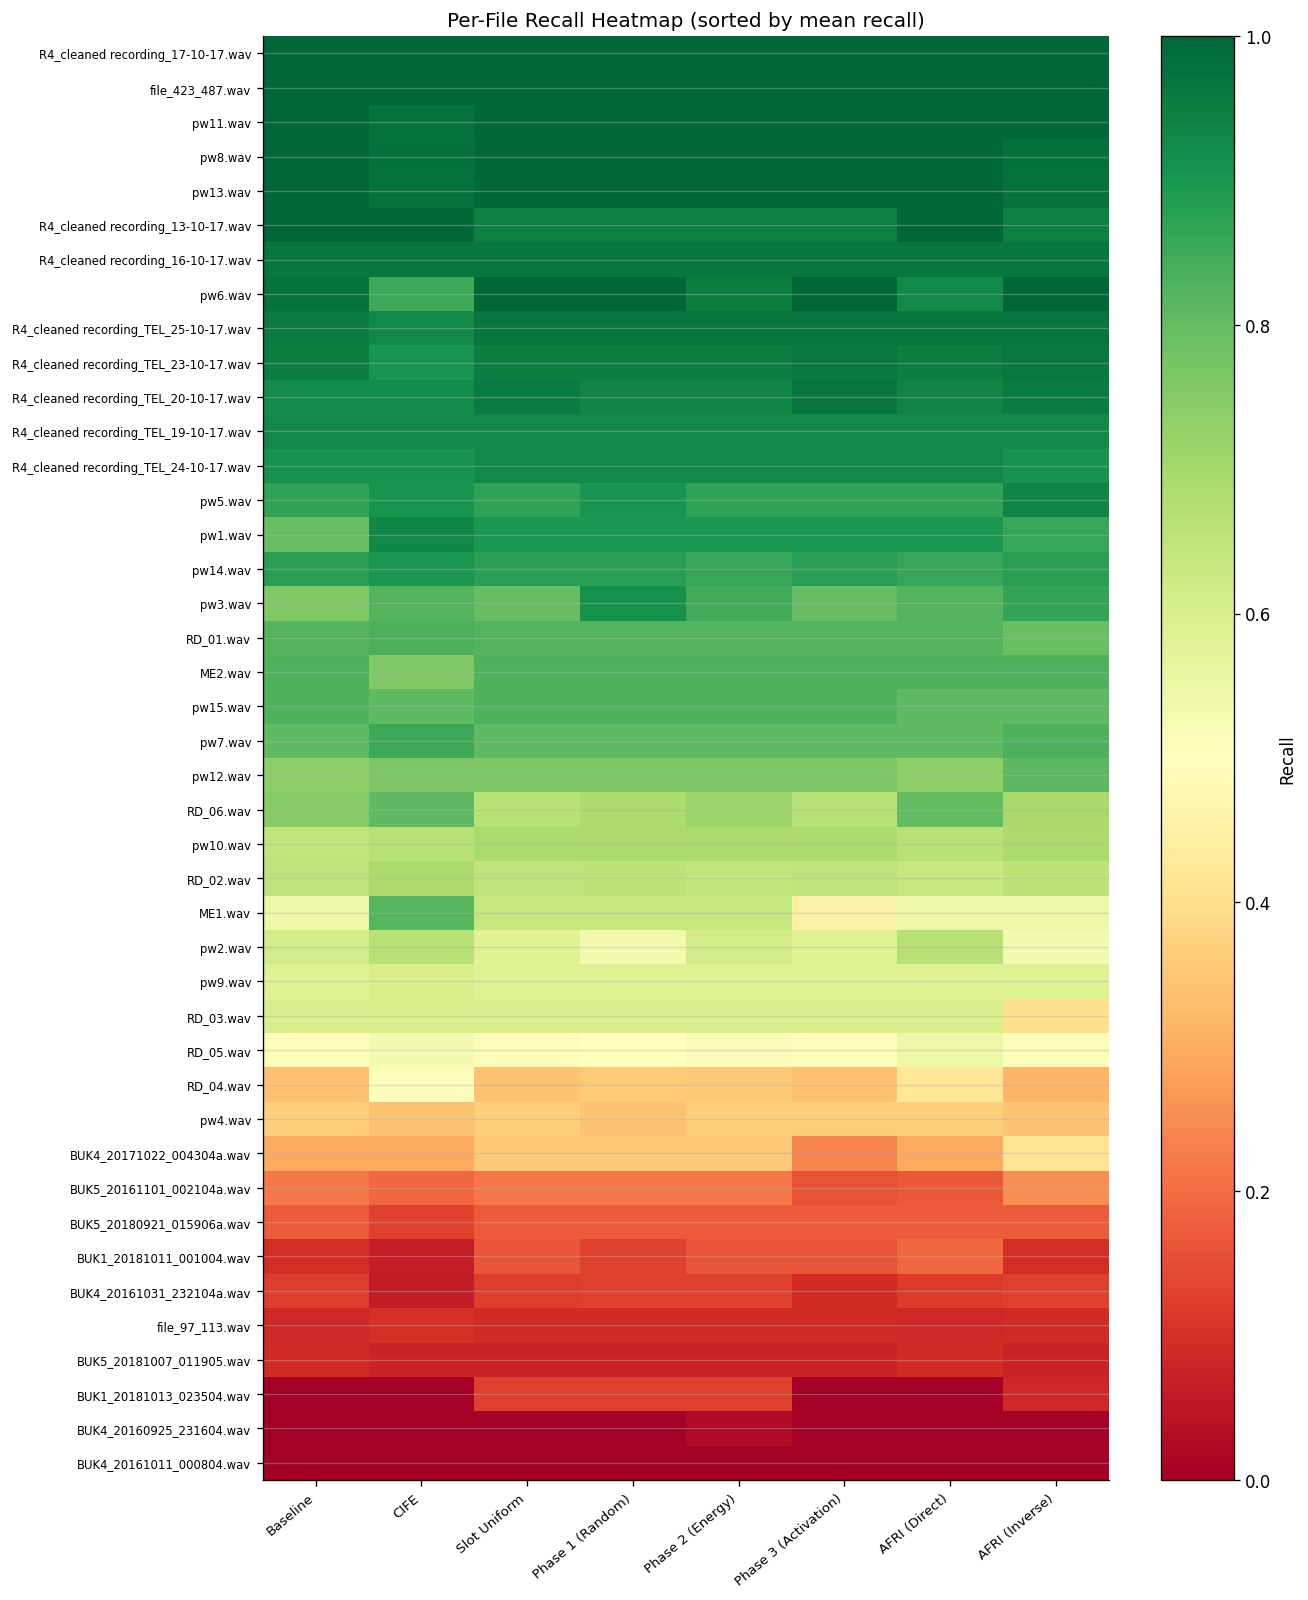

In [5]:
if not df_pf.empty:
    pivot_recall = df_pf.pivot_table(
        index="filename", columns="experiment", values="recall"
    ).reindex(columns=exp_labels)

    # Sort files by mean recall ascending (worst files at top)
    pivot_recall = pivot_recall.loc[pivot_recall.mean(axis=1).sort_values().index]

    fig, ax = plt.subplots(figsize=(max(8, len(exp_labels) * 1.4),
                                    max(8, len(pivot_recall) * 0.32)))
    im = ax.imshow(pivot_recall.values, aspect="auto", cmap="RdYlGn",
                   vmin=0, vmax=1, origin="lower")
    plt.colorbar(im, ax=ax, label="Recall")

    ax.set_xticks(range(len(exp_labels)))
    ax.set_xticklabels(exp_labels, rotation=40, ha="right", fontsize=8)
    ax.set_yticks(range(len(pivot_recall)))
    ax.set_yticklabels(pivot_recall.index, fontsize=7)
    ax.set_title("Per-File Recall Heatmap (sorted by mean recall)")
    plt.tight_layout()
    plt.savefig("fig_recall_heatmap.pdf", bbox_inches="tight")
    plt.show()

## 4 — F-measure Heatmap Across Experiments (per file)

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:11: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  # This is added back by InteractiveShellApp.init_path()


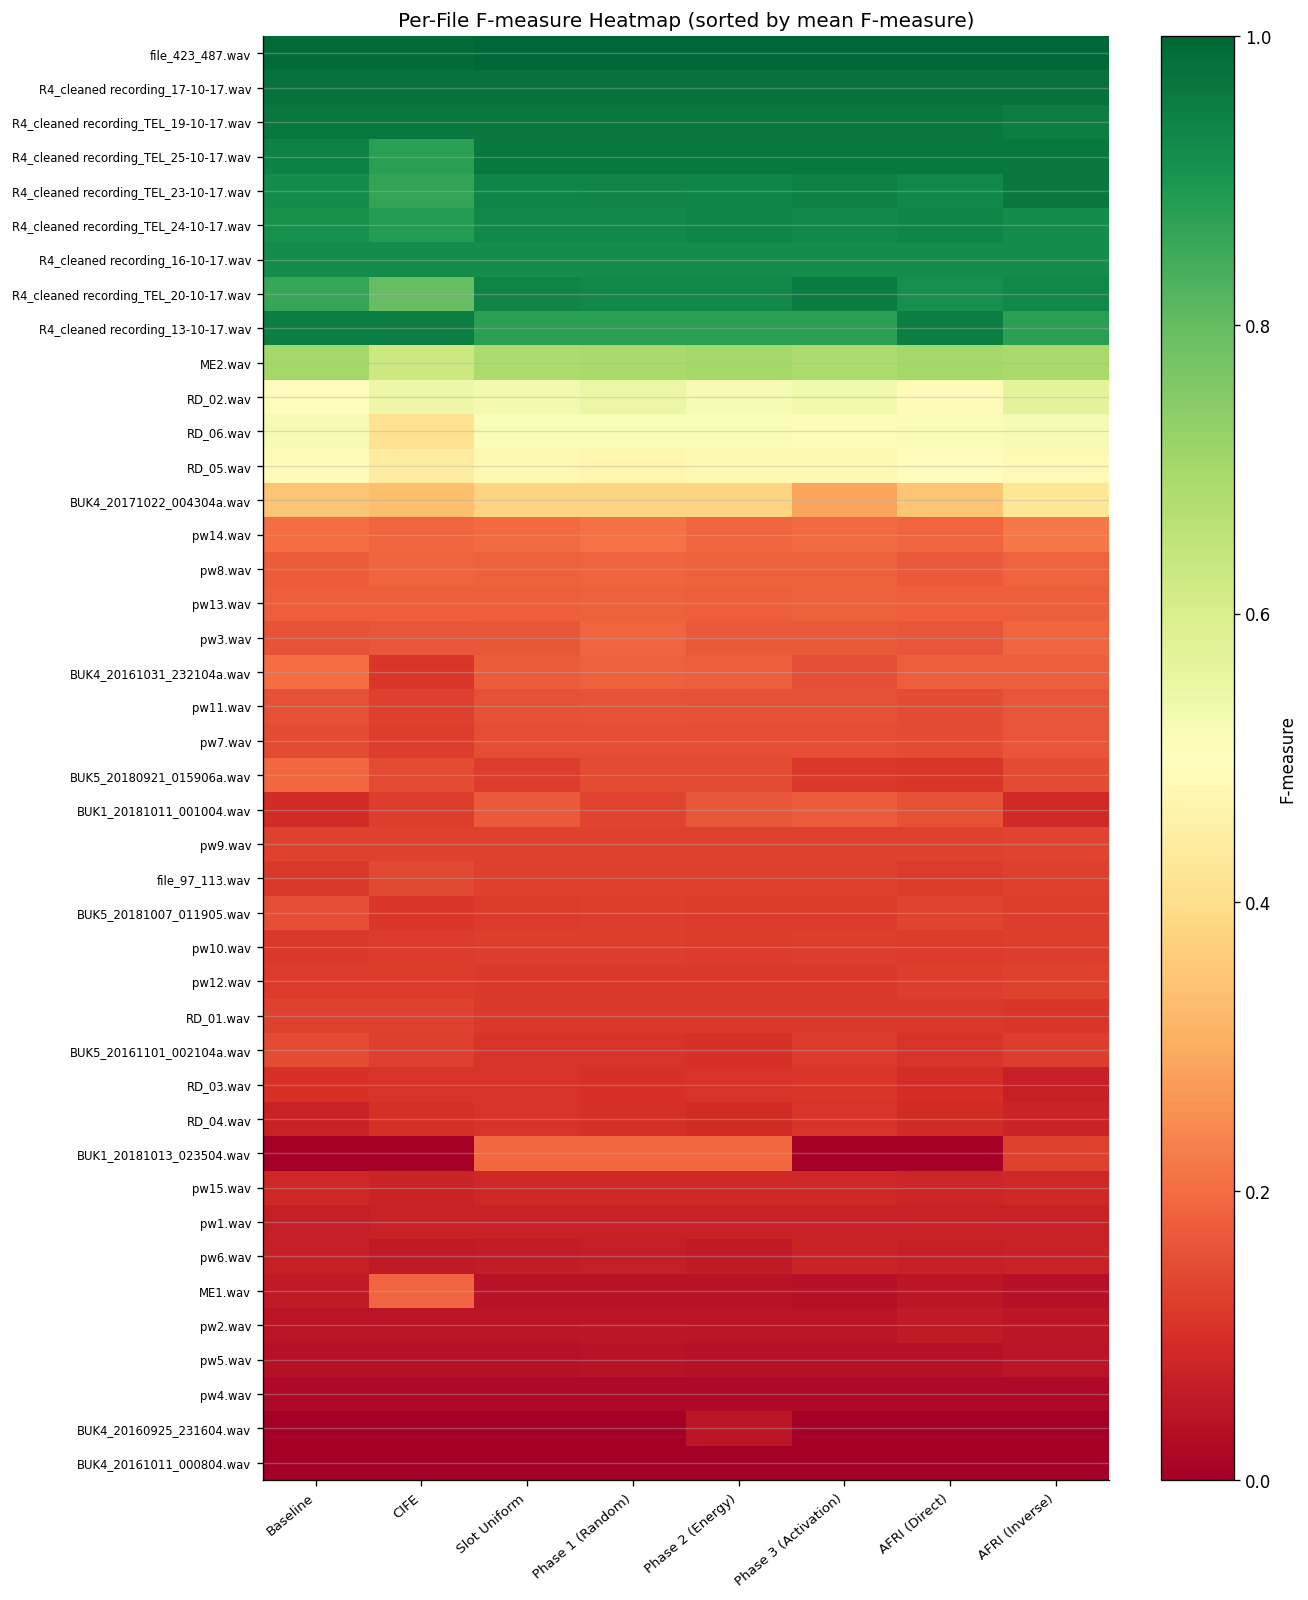

In [6]:
if not df_pf.empty:
    pivot_fm = df_pf.pivot_table(
        index="filename", columns="experiment", values="fmeasure"
    ).reindex(columns=exp_labels)
    pivot_fm = pivot_fm.loc[pivot_fm.mean(axis=1).sort_values().index]

    fig, ax = plt.subplots(figsize=(max(8, len(exp_labels) * 1.4),
                                    max(8, len(pivot_fm) * 0.32)))
    im = ax.imshow(pivot_fm.values, aspect="auto", cmap="RdYlGn",
                   vmin=0, vmax=1, origin="lower")
    plt.colorbar(im, ax=ax, label="F-measure")

    ax.set_xticks(range(len(exp_labels)))
    ax.set_xticklabels(exp_labels, rotation=40, ha="right", fontsize=8)
    ax.set_yticks(range(len(pivot_fm)))
    ax.set_yticklabels(pivot_fm.index, fontsize=7)
    ax.set_title("Per-File F-measure Heatmap (sorted by mean F-measure)")
    plt.tight_layout()
    plt.savefig("fig_fmeasure_heatmap.pdf", bbox_inches="tight")
    plt.show()

## 5 — Species / Subset Breakdown

Aggregated F-measure, precision, and recall per species subset (BUK, ME, R4, RD, PW).

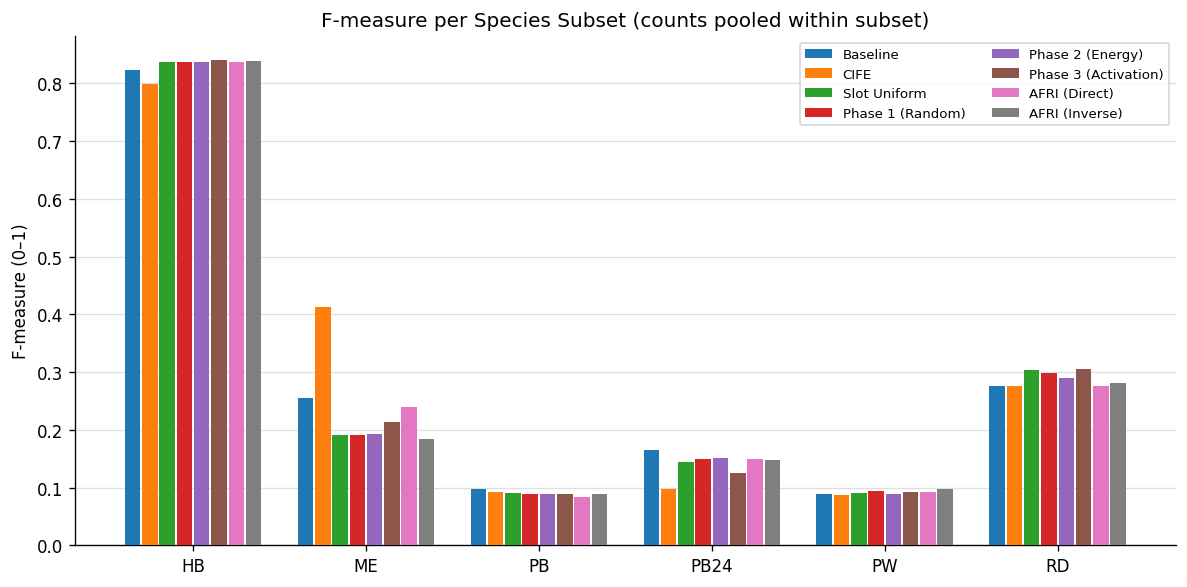

=== F-measure per Subset ===


subset,HB,ME,PB,PB24,PW,RD
experiment,,,,,,
AFRI (Direct),0.837,0.240,0.084,0.149,0.092,0.276
AFRI (Inverse),0.838,0.183,0.089,0.148,0.098,0.281
Baseline,0.823,0.256,0.098,0.165,0.089,0.276
CIFE,0.799,0.412,0.092,0.098,0.088,0.276
Phase 1 (Random),0.837,0.192,0.088,0.149,0.094,0.299
Phase 2 (Energy),0.837,0.193,0.089,0.151,0.089,0.289
Phase 3 (Activation),0.840,0.213,0.089,0.126,0.093,0.306
Slot Uniform,0.837,0.191,0.090,0.144,0.090,0.304


In [7]:
if not df_pf.empty:
    # Aggregate TP/FP/FN per (experiment, subset) then recompute scores
    agg = df_pf.groupby(["experiment", "subset"])[["TP", "FP", "FN"]].sum().reset_index()
    agg["precision"] = agg["TP"] / (agg["TP"] + agg["FP"]).clip(lower=1e-9)
    agg["recall"]    = agg["TP"] / (agg["TP"] + agg["FN"]).clip(lower=1e-9)
    agg["fmeasure"]  = agg["TP"] / (agg["TP"] + 0.5 * (agg["FP"] + agg["FN"])).clip(lower=1e-9)

    subsets = sorted(agg["subset"].unique())

    # ── Grouped bar: F-measure per subset per experiment ──────────────────
    x = np.arange(len(subsets))
    bar_w = 0.8 / max(len(exp_labels), 1)

    fig, ax = plt.subplots(figsize=(max(10, len(subsets) * 1.6), 5))
    for i_e, label in enumerate(exp_labels):
        sub = agg[agg["experiment"] == label].set_index("subset")
        vals = [sub.loc[s, "fmeasure"] if s in sub.index else 0.0 for s in subsets]
        offset = (i_e - len(exp_labels) / 2 + 0.5) * bar_w
        ax.bar(x + offset, vals, width=bar_w * 0.9,
               color=COLORS[i_e % len(COLORS)], label=label, zorder=3)

    ax.set_xticks(x)
    ax.set_xticklabels(subsets)
    ax.set_ylabel("F-measure (0–1)")
    ax.set_title("F-measure per Species Subset (counts pooled within subset)")
    ax.legend(loc="upper right", fontsize=8, ncol=2)
    plt.tight_layout()
    plt.savefig("fig_subset_fmeasure.pdf", bbox_inches="tight")
    plt.show()

    # ── Table ─────────────────────────────────────────────────────────────
    pivot_sub = agg.pivot_table(
        index="experiment", columns="subset", values="fmeasure"
    ).round(3)
    print("=== F-measure per Subset ===")
    display(pivot_sub)

## 6 — Subset Recall & Precision Heatmaps

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:14: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  


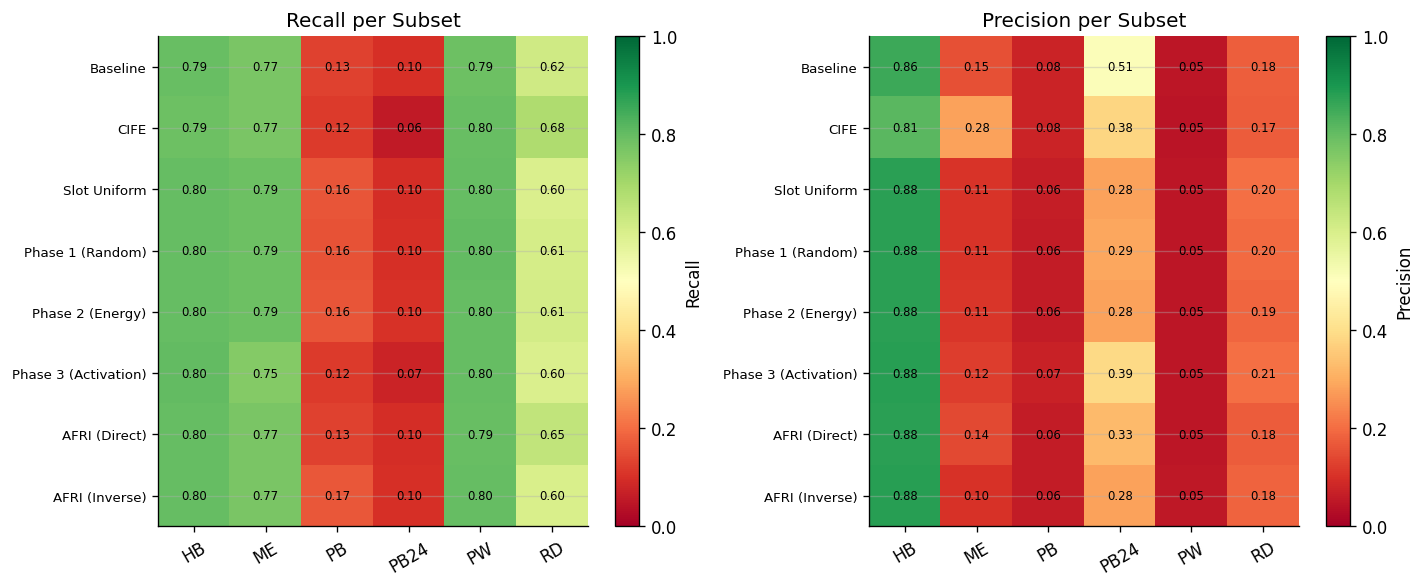

In [8]:
if not df_pf.empty:
    fig, axes = plt.subplots(1, 2, figsize=(max(12, len(subsets) * 2), 5))

    for ax, metric, title in zip(
        axes,
        ["recall", "precision"],
        ["Recall per Subset", "Precision per Subset"]
    ):
        pivot = agg.pivot_table(
            index="experiment", columns="subset", values=metric
        ).reindex(index=exp_labels, columns=subsets)

        im = ax.imshow(pivot.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=1)
        plt.colorbar(im, ax=ax, label=metric.capitalize())

        ax.set_xticks(range(len(subsets)))
        ax.set_xticklabels(subsets, rotation=30)
        ax.set_yticks(range(len(exp_labels)))
        ax.set_yticklabels(exp_labels, fontsize=8)

        # Annotate cells
        for r in range(pivot.values.shape[0]):
            for c in range(pivot.values.shape[1]):
                v = pivot.values[r, c]
                if not np.isnan(v):
                    ax.text(c, r, f"{v:.2f}", ha="center", va="center",
                            fontsize=7, color="black")
        ax.set_title(title)

    plt.tight_layout()
    plt.savefig("fig_subset_recall_precision.pdf", bbox_inches="tight")
    plt.show()

## 7 — Top False-Positive Files

Which audio files generate the most false positives?  
Useful for diagnosing where precision is worst.

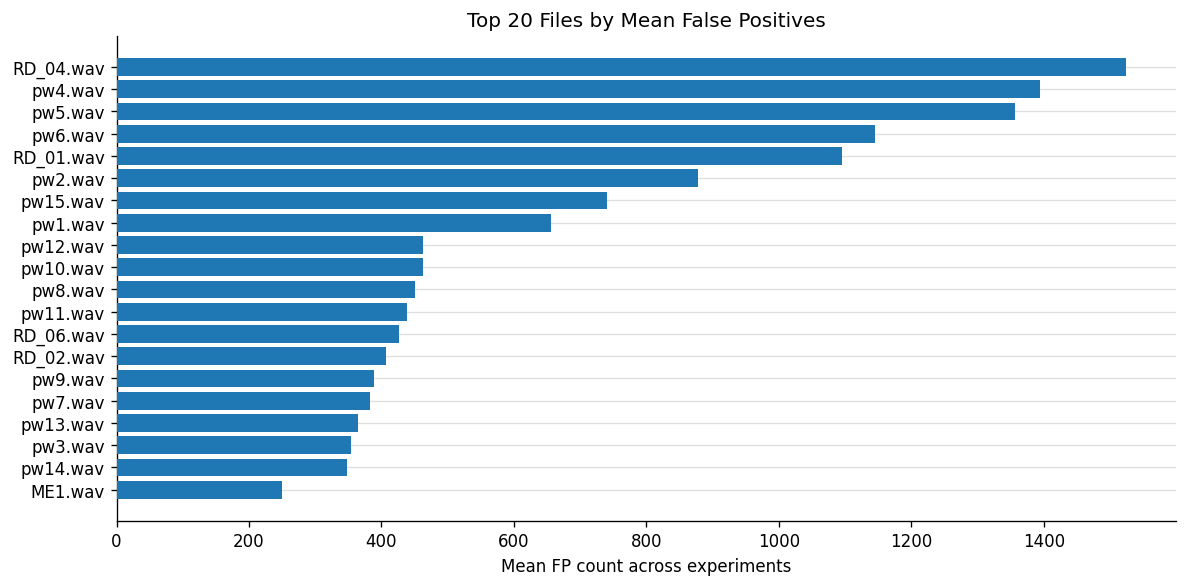

In [9]:
if not df_pf.empty:
    # Mean FP across experiments per file
    fp_mean = (
        df_pf.groupby("filename")["FP"]
        .mean()
        .sort_values(ascending=False)
        .head(20)
    )

    fig, ax = plt.subplots(figsize=(10, 5))
    colors_fp = [COLORS[0]] * len(fp_mean)
    ax.barh(fp_mean.index[::-1], fp_mean.values[::-1], color=colors_fp, zorder=3)
    ax.set_xlabel("Mean FP count across experiments")
    ax.set_title("Top 20 Files by Mean False Positives")
    plt.tight_layout()
    plt.savefig("fig_top_fp_files.pdf", bbox_inches="tight")
    plt.show()

## 8 — TP / FP / FN Stacked Bar per Experiment (selected file)

Pick any file from the list above to drill into.

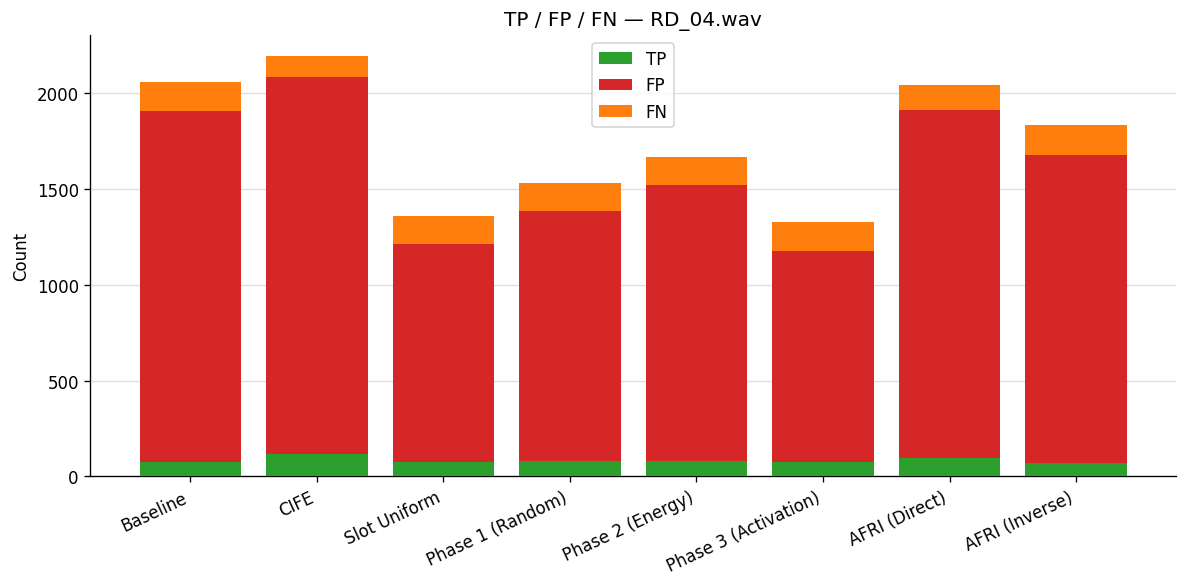

In [10]:
# ── Change this to any filename of interest ───────────────────────────────
SELECTED_FILE = fp_mean.index[0] if not df_pf.empty and not fp_mean.empty else None

if SELECTED_FILE and not df_pf.empty:
    sub = df_pf[df_pf["filename"] == SELECTED_FILE].set_index("experiment").reindex(exp_labels)

    x = np.arange(len(exp_labels))
    fig, ax = plt.subplots(figsize=(10, 5))

    tp_vals = sub["TP"].fillna(0).values
    fp_vals = sub["FP"].fillna(0).values
    fn_vals = sub["FN"].fillna(0).values

    bars_tp = ax.bar(x, tp_vals, label="TP", color="#2ca02c", zorder=3)
    bars_fp = ax.bar(x, fp_vals, bottom=tp_vals, label="FP", color="#d62728", zorder=3)
    bars_fn = ax.bar(x, fn_vals, bottom=tp_vals + fp_vals, label="FN", color="#ff7f0e", zorder=3)

    ax.set_xticks(x)
    ax.set_xticklabels(exp_labels, rotation=25, ha="right")
    ax.set_ylabel("Count")
    ax.set_title(f"TP / FP / FN — {SELECTED_FILE}")
    ax.legend()
    plt.tight_layout()
    plt.savefig(f"fig_tp_fp_fn_{SELECTED_FILE.replace('.wav','')}.pdf", bbox_inches="tight")
    plt.show()

## 9 — Delta F-measure vs Baseline (per file)

How much better/worse is each experiment vs the Baseline, per file?

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:16: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  


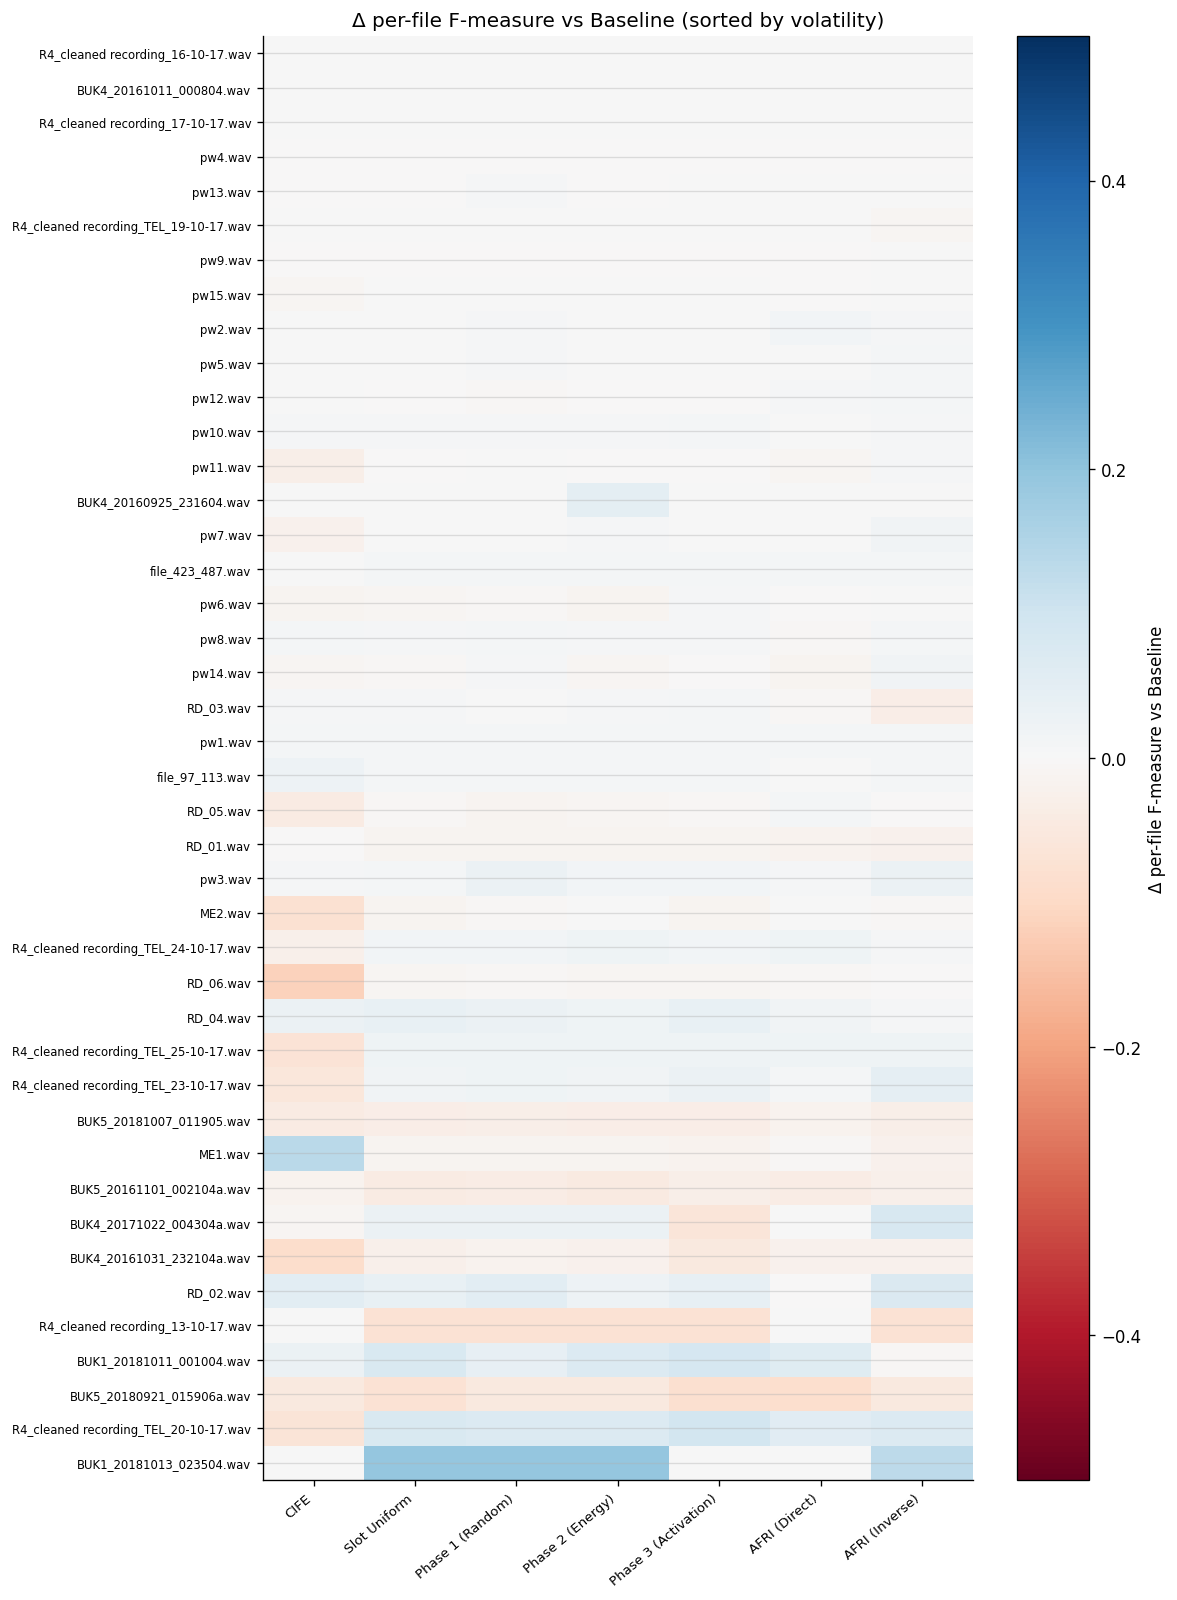

In [11]:
BASELINE_LABEL = "Baseline"  # Change if your baseline has a different label

if not df_pf.empty and BASELINE_LABEL in exp_labels:
    pivot_fm = df_pf.pivot_table(
        index="filename", columns="experiment", values="fmeasure"
    ).reindex(columns=exp_labels)

    # Delta vs baseline
    delta = pivot_fm.sub(pivot_fm[BASELINE_LABEL], axis=0).drop(columns=[BASELINE_LABEL])
    delta = delta.loc[delta.abs().mean(axis=1).sort_values(ascending=False).index]

    fig, ax = plt.subplots(figsize=(max(8, len(delta.columns) * 1.4),
                                    max(8, len(delta) * 0.32)))
    im = ax.imshow(delta.values, aspect="auto", cmap="RdBu",
                   vmin=-0.5, vmax=0.5, origin="lower")
    plt.colorbar(im, ax=ax, label="Δ per-file F-measure vs Baseline")

    ax.set_xticks(range(len(delta.columns)))
    ax.set_xticklabels(delta.columns, rotation=40, ha="right", fontsize=8)
    ax.set_yticks(range(len(delta)))
    ax.set_yticklabels(delta.index, fontsize=7)
    ax.set_title(f"Δ per-file F-measure vs {BASELINE_LABEL} (sorted by volatility)")
    plt.tight_layout()
    plt.savefig("fig_delta_vs_baseline.pdf", bbox_inches="tight")
    plt.show()
else:
    print(f"Baseline label '{BASELINE_LABEL}' not found in parsed experiments.")

## 8 — Paper figures (IEEE single/double column)

Two figures for `paper/final_draft_v2.tex`, sized and coloured for print. They
write **new** filenames into `paper/figures/` and leave every figure produced
above untouched.

| Cell | Output | Replaces in the draft |
|---|---|---|
| 8.1 | `fig_fp_concentration.pdf` | new; carries the silence mechanism |
| 8.2 | `fig_perfile_heatmap.pdf` | new; carries the per-recording remedy |

Both omit `ax.set_title` — the LaTeX `\caption` carries the title — and both
depend only on `df_pf`, `exp_labels` and `pl` from the cells above.

wrote ../../../paper/figures/fig_fp_concentration.pdf


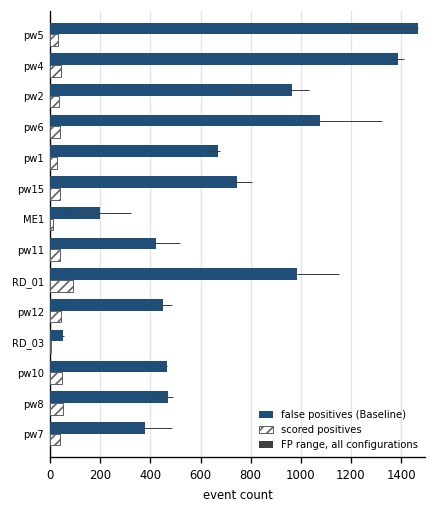


silent (file, configuration) pairs, for the caption:
  BUK1_20181013_023504.wav           Baseline
  BUK4_20160925_231604.wav           Baseline
  BUK4_20160925_231604.wav           CIFE

plotted recordings, FP / positives:
             fp   pos  ratio
filename                    
pw5.wav    1466  31.0  47.29
pw4.wav    1386  44.0  31.50
pw2.wav     965  36.0  26.81
pw6.wav    1075  41.0  26.22
pw1.wav     671  29.0  23.14
pw15.wav    744  41.0  18.15
ME1.wav     199  11.0  18.09
pw11.wav    424  39.0  10.87
RD_01.wav   985  91.0  10.82
pw12.wav    449  42.0  10.69
RD_03.wav    51   5.0  10.20
pw10.wav    465  48.0   9.69
pw8.wav     469  50.0   9.38
pw7.wav     379  41.0   9.24


In [12]:
# ── Paper figure: false-alarm concentration per recording ──────────────────
# Job: show FP against scored positives per recording, so the silence effect
# reads as a property of the validation set rather than of two hand-picked
# files. Recordings whose FP exceeds their positives are the ones a system
# profits by going silent on.
#
# Scored positives = TP + FN, taken only from rows where the configuration
# actually predicted on the file. A silent configuration has its FN backfilled
# with the raw POS count (support shots included), so those rows overstate the
# positives -- and the baseline is itself silent on one file, so the positives
# cannot come from the baseline alone.
#
# Writes fig_fp_concentration.pdf. Does not touch fig_top_fp_files.pdf.

from pathlib import Path
from matplotlib.patches import Patch

FIG_DIR = Path("../../../paper/figures")
if not FIG_DIR.is_dir():
    FIG_DIR = Path(".")

N_SHOW      = 14          # 20 rows costs more column than it earns
FP_SOURCE   = "Baseline"  # bars match the counts quoted in the text
SHOW_SPREAD = True        # thin whisker: min-max FP across configurations
ACCENT      = "#1f4e79"   # FP, recordings above the boundary
CONTEXT     = "#9aa0a6"   # FP, recordings below it
POSFILL     = "#ffffff"   # positives: white + hatch, legible in grayscale


def _short(name, width=19):
    """Filename trimmed for a single-column axis."""
    stem = name[:-4] if name.lower().endswith(".wav") else name
    if len(stem) <= width:
        return stem
    return stem[:width - 9] + "…" + stem[-8:]


if df_pf.empty:
    print("Per-file data not available.")
elif FP_SOURCE not in exp_labels:
    print("FP_SOURCE %r not among %r" % (FP_SOURCE, exp_labels))
else:
    live = df_pf[~df_pf["from_backfill"]].copy()
    live["pos"] = live["TP"] + live["FN"]
    # TP+FN is an annotation property, constant across non-silent runs; median
    # is a safe reducer rather than a claim about spread.
    pos = live.groupby("filename")["pos"].median()

    fp_wide = df_pf.pivot_table(index="filename", columns="experiment",
                                values="FP").reindex(columns=exp_labels)
    fp = fp_wide[FP_SOURCE]

    d = pd.DataFrame({"pos": pos, "fp": fp}).dropna()
    d = d[d["pos"] > 0]
    d["ratio"] = d["fp"] / d["pos"]
    d = d.sort_values("ratio", ascending=False).head(N_SHOW)

    n = len(d)
    y = np.arange(n)[::-1]          # highest ratio at the top
    h = 0.38
    over = (d["ratio"] > 1.0).values

    with plt.rc_context({"font.size": 7, "axes.grid": False,
                         "axes.spines.top": False, "axes.spines.right": False}):
        fig, ax = plt.subplots(figsize=(3.5, 0.235 * n + 0.85))

        ax.barh(y + h / 2, d["fp"].values, height=h, zorder=3,
                color=[ACCENT if o else CONTEXT for o in over],
                edgecolor="none")
        ax.barh(y - h / 2, d["pos"].values, height=h, zorder=3,
                facecolor=POSFILL, edgecolor="#5f6368",
                linewidth=0.6, hatch="////")

        if SHOW_SPREAD:
            lo = fp_wide.loc[d.index].min(axis=1).values
            hi = fp_wide.loc[d.index].max(axis=1).values
            ax.hlines(y + h / 2, lo, hi, color="#3c4043",
                      linewidth=0.6, zorder=4)

        # Boundary between FP > positives and FP <= positives. Sorting by ratio
        # makes the crossing monotone, so it is a single line.
        n_over = int(over.sum())
        if 0 < n_over < n:
            edge = y[n_over - 1] - 0.5
            ax.axhline(edge, color="#3c4043", linewidth=0.7,
                       linestyle=(0, (3, 2)), zorder=5)
            ax.annotate("FP > positives above", xy=(0.985, edge),
                        xycoords=("axes fraction", "data"),
                        xytext=(0, 2.5), textcoords="offset points",
                        ha="right", va="bottom", fontsize=6, color="#3c4043")

        ax.set_yticks(y)
        ax.set_yticklabels([_short(f) for f in d.index], fontsize=6)
        ax.set_xlabel("event count")
        ax.set_ylim(-0.75, n - 0.25)
        ax.margins(x=0.02)
        ax.tick_params(axis="y", length=0)
        ax.xaxis.grid(True, alpha=0.35, zorder=0)
        ax.set_axisbelow(True)

        handles = [
            Patch(facecolor=ACCENT, edgecolor="none",
                  label="false positives (%s)" % FP_SOURCE),
            Patch(facecolor=POSFILL, edgecolor="#5f6368", hatch="////",
                  linewidth=0.6, label="scored positives"),
        ]
        if SHOW_SPREAD:
            handles.append(Patch(facecolor="#3c4043", edgecolor="none",
                                 label="FP range, all configurations"))
        ax.legend(handles=handles, loc="lower right", fontsize=6,
                  frameon=False, handlelength=1.4, borderaxespad=0.3)

        fig.tight_layout(pad=0.3)
        out = FIG_DIR / "fig_fp_concentration.pdf"
        fig.savefig(out, bbox_inches="tight")
        print("wrote %s" % out)
        plt.show()

    silent = df_pf[df_pf["from_backfill"]]
    if not silent.empty:
        print("\nsilent (file, configuration) pairs, for the caption:")
        for _, r in silent.sort_values(["filename", "experiment"]).iterrows():
            print("  %-34s %s" % (r["filename"], r["experiment"]))
    print("\nplotted recordings, FP / positives:")
    print(d[["fp", "pos", "ratio"]].round(2).to_string())

### 8.2 — Per-recording F-measure heatmap

`TRANSPOSE = True` gives configurations as rows and recordings as columns, sized
for `\begin{figure*}` across both columns; the horizontal bands make "the
configurations are nearly indistinguishable" the first thing the eye reads. Set
it to `False` for a tall single-column portrait version instead.

wrote ../../../paper/figures/fig_perfile_heatmap.pdf


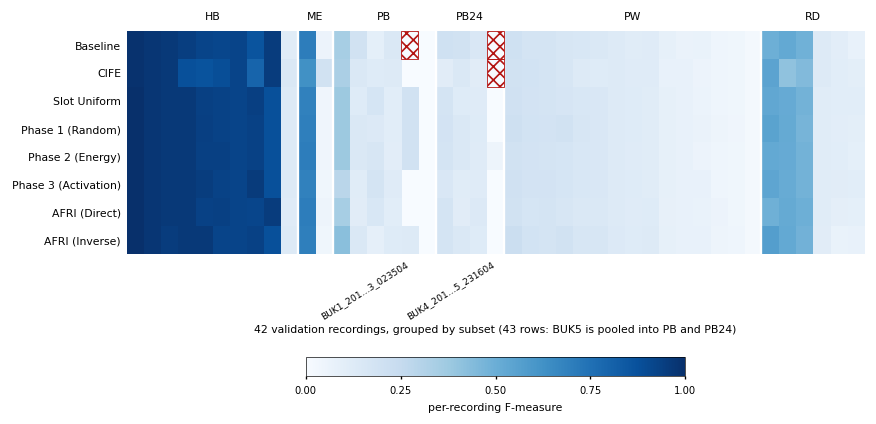

rows per subset: {'HB': 10, 'ME': 2, 'PB': 6, 'PB24': 4, 'PW': 15, 'RD': 6}
median per-recording F, by configuration:
experiment
Baseline                0.1554
CIFE                    0.1429
Slot Uniform            0.1545
Phase 1 (Random)        0.1490
Phase 2 (Energy)        0.1532
Phase 3 (Activation)    0.1490
AFRI (Direct)           0.1467
AFRI (Inverse)          0.1455
recordings scoring 0 under every configuration: 1 of 43

caption must state: hatched cells are recordings for which that configuration returned no predictions.
hatched: BUK1_20181013_023504.wav, BUK4_20160925_231604.wav


In [13]:
# ── Paper figure: per-recording F-measure across configurations ────────────
# Job: show what scoring each recording separately produces -- the paper's
# proposed remedy. Three things become visible at once: most recordings score
# near zero while a handful carry every subset, the seven configurations are
# nearly indistinguishable recording by recording, and a silent recording is a
# hard zero rather than a subset gain.
#
# Rows are grouped by pooling subset, not sorted globally, because the argument
# is about which recordings share a pool. BUK5 is pooled into both PB and PB24,
# so it appears in both groups: 43 rows over 42 distinct recordings.
#
# Colour is sequential single-hue (magnitude, 0 to 1): survives grayscale
# printing and colour-vision deficiency, which RdYlGn does not.
#
# Writes fig_perfile_heatmap.pdf. Does not touch fig_fmeasure_heatmap.pdf.

from pathlib import Path
from matplotlib.patches import Rectangle

FIG_DIR = Path("../../../paper/figures")
if not FIG_DIR.is_dir():
    FIG_DIR = Path(".")

SUBSET_ORDER = ["HB", "ME", "PB", "PB24", "PW", "RD"]
TRANSPOSE    = True        # True: configurations as rows -> \begin{figure*}
                           # False: recordings as rows -> single column, tall
CMAP         = "Blues"     # one hue, light to dark
LABEL_SILENT = True        # name only the recordings a configuration went silent on

if df_pf.empty:
    print("Per-file data not available.")
else:
    ex = df_pf.assign(subset=[pl.subsets_of(f) for f in df_pf["filename"]])
    ex = ex.explode("subset")
    ex["fb"] = ex["from_backfill"].astype(int)

    piv = ex.pivot_table(index=["subset", "filename"], columns="experiment",
                         values="fmeasure").reindex(columns=exp_labels)
    sil = ex.pivot_table(index=["subset", "filename"], columns="experiment",
                         values="fb", aggfunc="max").reindex(columns=exp_labels)

    # Group by subset in the challenge's order; within a group, strongest first.
    subs = [s for s in SUBSET_ORDER if s in set(piv.index.get_level_values("subset"))]
    subs += [s for s in sorted(set(piv.index.get_level_values("subset"))) if s not in subs]
    order, sizes = [], []
    for s in subs:
        blk = piv[piv.index.get_level_values("subset") == s]
        blk = blk.loc[blk.mean(axis=1).sort_values(ascending=False).index]
        order.extend(list(blk.index))
        sizes.append(len(blk))
    piv = piv.loc[order]
    sil = sil.reindex(order).fillna(0).astype(int)

    names = [f for (_s, f) in piv.index]
    bounds = np.cumsum(sizes)                      # group edges, last == n_rec
    centres = bounds - np.array(sizes) / 2.0 - 0.5
    n_rec, n_exp = piv.shape

    def _short(name, width=17):
        stem = name[:-4] if name.lower().endswith(".wav") else name
        if len(stem) <= width:
            return stem
        return stem[:width - 9] + "…" + stem[-8:]

    silent_rows = sorted(set(np.nonzero(sil.values.sum(axis=1))[0].tolist()))

    with plt.rc_context({"font.size": 7, "axes.grid": False,
                         "axes.spines.top": False, "axes.spines.right": False,
                         "axes.spines.left": False, "axes.spines.bottom": False}):
        if TRANSPOSE:
            data = piv.values.T                     # configurations x recordings
            mask = sil.values.T
            fig, ax = plt.subplots(figsize=(7.16, 0.23 * n_exp + 1.55))
        else:
            data = piv.values                       # recordings x configurations
            mask = sil.values
            fig, ax = plt.subplots(figsize=(3.5, 0.105 * n_rec + 1.35))

        im = ax.imshow(data, aspect="auto", cmap=CMAP, vmin=0.0, vmax=1.0,
                       interpolation="nearest")

        # A silent recording scores a true zero; hatch it so the cell cannot be
        # mistaken for missing data.
        for r, c in zip(*np.nonzero(mask)):
            ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False,
                                   hatch="xxx", edgecolor="#b31412",
                                   linewidth=0.5, zorder=4))

        if TRANSPOSE:
            ax.set_yticks(np.arange(n_exp))
            ax.set_yticklabels(exp_labels, fontsize=6.5)
            for b in bounds[:-1]:
                ax.axvline(b - 0.5, color="white", linewidth=1.4, zorder=3)
            for s, cx in zip(subs, centres):
                ax.text(cx, -0.85, s, ha="center", va="bottom", fontsize=6.5)
            if LABEL_SILENT and silent_rows:
                ax.set_xticks(silent_rows)
                ax.set_xticklabels([_short(names[i]) for i in silent_rows],
                                   rotation=32, ha="right", fontsize=5.5)
            else:
                ax.set_xticks([])
            ax.set_xlabel("42 validation recordings, grouped by subset "
                          "(43 rows: BUK5 is pooled into PB and PB24)",
                          fontsize=6.5, labelpad=2)
        else:
            ax.set_xticks(np.arange(n_exp))
            ax.set_xticklabels(exp_labels, rotation=38, ha="right", fontsize=6.5)
            for b in bounds[:-1]:
                ax.axhline(b - 0.5, color="white", linewidth=1.4, zorder=3)
            ax.set_yticks(centres)
            ax.set_yticklabels(subs, fontsize=6.5)
            ax.set_ylabel("recordings, grouped by subset", fontsize=6.5)
            # Portrait mode hatches the silent cells but has no room to name
            # them; the caption names them instead.

        ax.tick_params(length=0)

        cb = fig.colorbar(im, ax=ax, orientation="horizontal",
                          fraction=0.055, pad=0.30 if TRANSPOSE else 0.12,
                          ticks=[0, 0.25, 0.5, 0.75, 1.0])
        cb.set_label("per-recording F-measure", fontsize=6.5)
        cb.ax.tick_params(labelsize=6, length=2)
        cb.outline.set_linewidth(0.4)

        # No legend: in transposed mode it would land on top of the subset
        # labels above the first row. One mark type, so the caption carries it
        # (see the reminder printed below).

        fig.tight_layout(pad=0.3)
        out = FIG_DIR / "fig_perfile_heatmap.pdf"
        fig.savefig(out, bbox_inches="tight")
        print("wrote %s" % out)
        plt.show()

    print("rows per subset: %s" % dict(zip(subs, sizes)))
    print("median per-recording F, by configuration:")
    print(piv.median(axis=0).round(4).to_string())
    print("recordings scoring 0 under every configuration: %d of %d"
          % (int((piv.fillna(0).max(axis=1) == 0).sum()), n_rec))
    print("\ncaption must state: hatched cells are recordings for which that "
          "configuration returned no predictions.")
    if silent_rows:
        print("hatched: %s" % ", ".join(names[i] for i in silent_rows))